# Penentuan Split Train / Validasi / Test Berbasis Pola Periode (Selat Sunda)

Tujuan notebook ini adalah menentukan titik potong data **berdasarkan pola periode** di data chl-a, bukan dengan proporsi baku (80:20 atau 90:10).

**Alasan**

Variabilitas chl-a di Selat Sunda dipengaruhi kejadian iklim antar-tahun (misalnya IOD positif dan El Niño) yang memicu upwelling dan *bloom*. Kejadian seperti ini tidak tersebar merata dalam waktu. Kalau split dibuat dengan proporsi baku, bisa terjadi bagian train hampir tidak pernah melihat kejadian ekstrem, sementara bagian test justru penuh kejadian ekstrem (atau sebaliknya). Akibatnya hasil evaluasi model bergantung pada kebetulan letak kejadian, bukan pada kemampuan model.

**Kriteria split yang baik**

1. **Berurutan waktu** (tidak diacak), supaya tidak ada kebocoran informasi masa depan.
2. **Dipotong di batas tahun penuh**, supaya semua musim terwakili seimbang di tiap bagian.
3. **Tiga bagian**: train (melatih), validasi (tuning hiperparameter, *early stopping*), test (evaluasi akhir, hanya dipakai sekali).
4. **Setiap bagian memuat kondisi normal dan minimal satu kejadian ekstrem**, supaya model belajar dan diuji pada kondisi yang beragam.
5. **Distribusi anomali di tiap bagian tidak jauh berbeda**, diukur dengan statistik KS.
6. **Train cukup panjang** untuk membentuk klimatologi yang stabil (idealnya ≥ 12 tahun).

**Catatan metodologis**

Anomali di notebook ini dihitung dengan **klimatologi seluruh periode (2003–2025)**, karena tujuannya **deskriptif**: mengenali pola dan kejadian. Untuk pemodelan, klimatologi tetap harus dihitung dari periode train saja, dengan menjalankan ulang notebook cleaning setelah `TRAIN_END` dipilih.

## 0. Konfigurasi

In [2]:
import json
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.width', 170)
pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25})

# ------------------ KONFIGURASI ------------------
REGION = 'selat_sunda'
TAG = '200301_202512_v1'
ROOT = Path(os.environ.get('THESIS_ROOT', r'D:/thesis'))
PANEL_PATH = ROOT / 'data' / 'processed' / 'clean' / f'clean_panel_{REGION}_{TAG}.csv'
TABLE_DIR = ROOT / 'output' / 'tables' / 'split'
FIG_DIR = ROOT / 'output' / 'figures' / 'split'

# Opsional: indeks iklim eksternal. CSV dengan kolom 'month' (YYYY-MM) dan kolom indeks.
# DMI (IOD) dari NOAA PSL / BoM, ONI (ENSO) dari NOAA CPC. Biarkan bila belum ada.
INDEX_PATH = ROOT / 'data' / 'external' / 'climate_indices.csv'

MIN_GRID_SHARE = 0.5     # bulan dipakai di deret regional bila >= 50% grid teramati
EXTREME_Z = 2.0          # bulan ekstrem: |anomali regional| > 2 simpangan baku
P90_EXTENT = 0.30        # bulan 'meluas' bila >= 30% grid melebihi persentil 90 grid itu sendiri

# Kandidat split. train_end dan val_end inklusif. val_end=None berarti tanpa validasi.
CANDIDATES = {
    'Baku 80:20':              {'train_end': None, 'val_end': None, 'frac': 0.8},
    'Split EDA (s.d. 2018)':   {'train_end': '2018-12', 'val_end': None},
    'Usulan A (2016|2020)':    {'train_end': '2016-12', 'val_end': '2020-12'},
    'Usulan B (2017|2020)':    {'train_end': '2017-12', 'val_end': '2020-12'},
    'Usulan C (2015|2019)':    {'train_end': '2015-12', 'val_end': '2019-12'},
    'Usulan D (2016|2019)':    {'train_end': '2016-12', 'val_end': '2019-12'},
}
# --------------------------------------------------

TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
SEASON = {12: 'DJF', 1: 'DJF', 2: 'DJF', 3: 'MAM', 4: 'MAM', 5: 'MAM',
          6: 'JJA', 7: 'JJA', 8: 'JJA', 9: 'SON', 10: 'SON', 11: 'SON'}

def save_fig(fig, name):
    fig.savefig(FIG_DIR / f'{name}_{REGION}_{TAG}.png', dpi=200, bbox_inches='tight')

def save_table(df, name, index=True):
    df.to_csv(TABLE_DIR / f'{name}_{REGION}_{TAG}.csv', index=index, encoding='utf-8-sig')

print(('ADA   ' if PANEL_PATH.is_file() else 'TIDAK ') + str(PANEL_PATH))
print(('ADA   ' if INDEX_PATH.is_file() else 'TIDAK (opsional) ') + str(INDEX_PATH))

ADA   D:\thesis\data\processed\clean\clean_panel_selat_sunda_200301_202512_v1.csv
ADA   D:\thesis\data\external\climate_indices.csv


## 1. Muat panel bersih dan hitung anomali deskriptif

Hanya grid-bulan *reliable* yang dipakai. Anomali deskriptif = `y` − rata-rata `y` per (grid, bulan kalender) dari **seluruh periode**. Lalu dibuat deret **regional** (rata-rata semua grid per bulan), dipakai bila minimal `MIN_GRID_SHARE` grid teramati.

In [3]:
usecols = ['month', 'grid_id', 'cal_month', 'reliable', 'y', 'flag_outlier', 'flag_coastal']
p = pd.read_csv(PANEL_PATH, usecols=usecols, parse_dates=['month'], dtype={'grid_id': str}, encoding='utf-8-sig')
p['reliable'] = p.reliable.astype(str).str.lower().isin(['true', '1'])
p = p[p.reliable & p.y.notna()].copy()
p['clim_full'] = p.groupby(['grid_id', 'cal_month']).y.transform('mean')
p['anom'] = p.y - p.clim_full

A = p.pivot(index='month', columns='grid_id', values='anom')
all_months = pd.date_range(A.index.min(), A.index.max(), freq='MS')
A = A.reindex(all_months)
share = A.notna().mean(axis=1)
reg = A.mean(axis=1).where(share >= MIN_GRID_SHARE)
SD = reg.std()
reg_z = reg / SD

# Luasan: proporsi grid yang anomalinya > persentil 90 grid itu sendiri
p90 = A.quantile(.90)
extent = (A.gt(p90, axis=1)).sum(axis=1) / A.notna().sum(axis=1).replace(0, np.nan)

ts = pd.DataFrame({'anom_reg': reg, 'z': reg_z, 'extent_p90': extent, 'grid_share': share})
ts['year'] = ts.index.year
ts['cal_month'] = ts.index.month
ts['season'] = ts.cal_month.map(SEASON)
ts['ekstrem_pos'] = ts.z > EXTREME_Z
ts['ekstrem_neg'] = ts.z < -EXTREME_Z
ts['meluas'] = ts.extent_p90 >= P90_EXTENT

print(f'Bulan: {len(ts)} | dipakai di deret regional: {int(reg.notna().sum())} | SD anomali regional = {SD:.3f} log10')
print(f"Bulan ekstrem positif: {int(ts.ekstrem_pos.sum())} | ekstrem negatif: {int(ts.ekstrem_neg.sum())} | meluas (>= {P90_EXTENT:.0%} grid > p90): {int(ts.meluas.sum())}")
display(ts[ts.ekstrem_pos | ts.ekstrem_neg][['anom_reg', 'z', 'extent_p90', 'season']].round(3))
save_table(ts, 'deret_regional')

Bulan: 276 | dipakai di deret regional: 272 | SD anomali regional = 0.193 log10
Bulan ekstrem positif: 14 | ekstrem negatif: 2 | meluas (>= 30% grid > p90): 34


,anom_reg,z,extent_p90,season
2003-07-01,0.489,2.537,0.770,JJA
2006-09-01,0.447,2.318,0.730,SON
2006-10-01,0.557,2.889,0.845,SON
2006-11-01,0.623,3.232,0.871,SON
2006-12-01,0.447,2.318,0.735,DJF
2011-09-01,0.545,2.825,0.791,SON
2016-08-01,-0.394,-2.042,0.000,JJA
2016-09-01,-0.443,-2.298,0.000,SON
2019-09-01,0.424,2.199,0.655,SON
2019-10-01,0.513,2.661,0.843,SON


## 2. Deret waktu anomali regional dan kejadian ekstrem

Grafik atas: anomali regional bulanan, dengan bulan ekstrem ditandai. Grafik bawah: proporsi grid yang anomalinya di atas persentil 90 masing-masing grid, yang menunjukkan **seberapa luas** kejadian itu secara spasial.

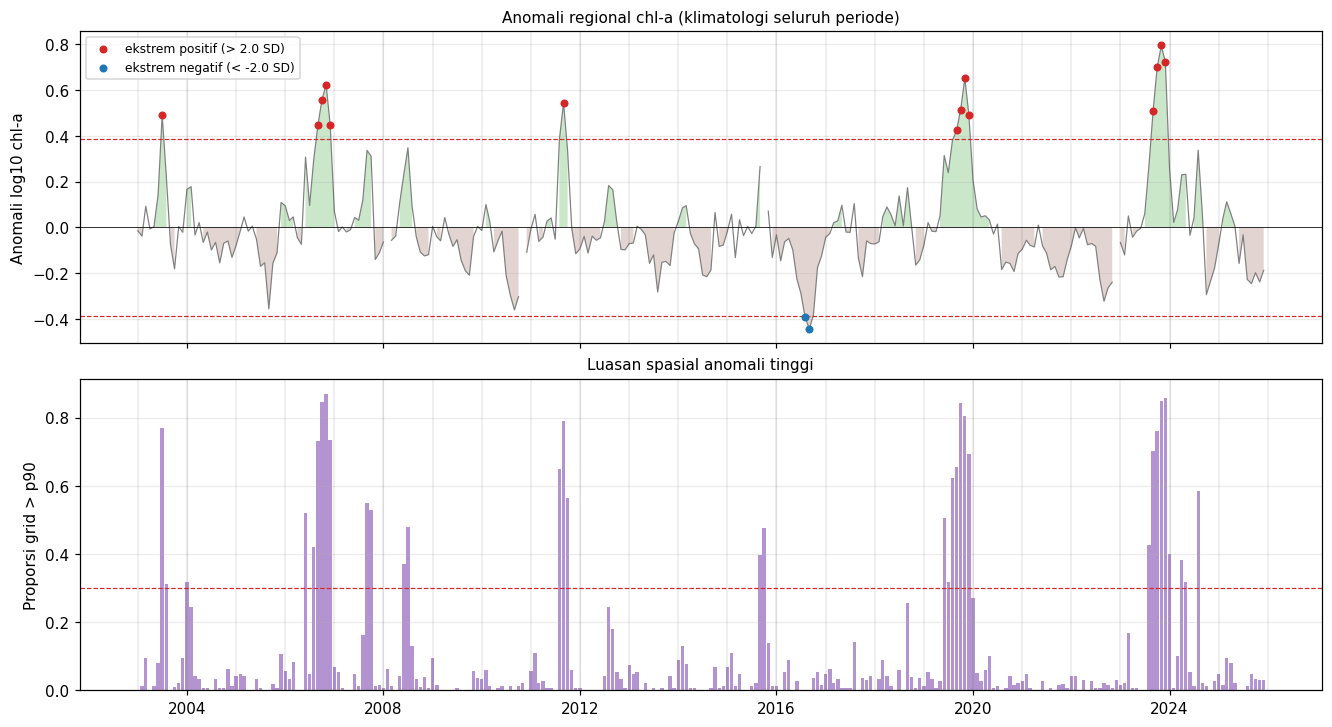

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True, constrained_layout=True)
ax = axes[0]
ax.plot(ts.index, ts.anom_reg, color='gray', lw=.8)
ax.fill_between(ts.index, 0, ts.anom_reg, where=ts.anom_reg > 0, color='tab:green', alpha=.25, lw=0)
ax.fill_between(ts.index, 0, ts.anom_reg, where=ts.anom_reg < 0, color='tab:brown', alpha=.25, lw=0)
for lvl in (EXTREME_Z, -EXTREME_Z):
    ax.axhline(lvl * SD, color='tab:red', ls='--', lw=.8)
ax.scatter(ts.index[ts.ekstrem_pos], ts.anom_reg[ts.ekstrem_pos], color='tab:red', s=18, zorder=3, label=f'ekstrem positif (> {EXTREME_Z} SD)')
ax.scatter(ts.index[ts.ekstrem_neg], ts.anom_reg[ts.ekstrem_neg], color='tab:blue', s=18, zorder=3, label=f'ekstrem negatif (< -{EXTREME_Z} SD)')
ax.axhline(0, color='k', lw=.5); ax.set_ylabel('Anomali log10 chl-a'); ax.legend(fontsize=8, loc='upper left')
ax.set_title('Anomali regional chl-a (klimatologi seluruh periode)', fontsize=10)

ax = axes[1]
ax.bar(ts.index, ts.extent_p90, width=25, color='tab:purple', alpha=.7)
ax.axhline(P90_EXTENT, color='tab:red', ls='--', lw=.8)
ax.set_ylabel('Proporsi grid > p90'); ax.set_title('Luasan spasial anomali tinggi', fontsize=10)
for a in axes:
    for yr in range(ts.index.year.min(), ts.index.year.max() + 2):
        a.axvline(pd.Timestamp(f'{yr}-01-01'), color='k', lw=.2, alpha=.4)
save_fig(fig, 'deret_anomali_ekstrem'); plt.show()

## 3. Pola per tahun dan per musim

Heatmap tahun × bulan memperlihatkan **periode** dengan jelas: tahun mana yang anomali positifnya kuat dan pada bulan apa. Untuk Selat Sunda, kejadian upwelling kuat biasanya tampak di Agustus–Desember.

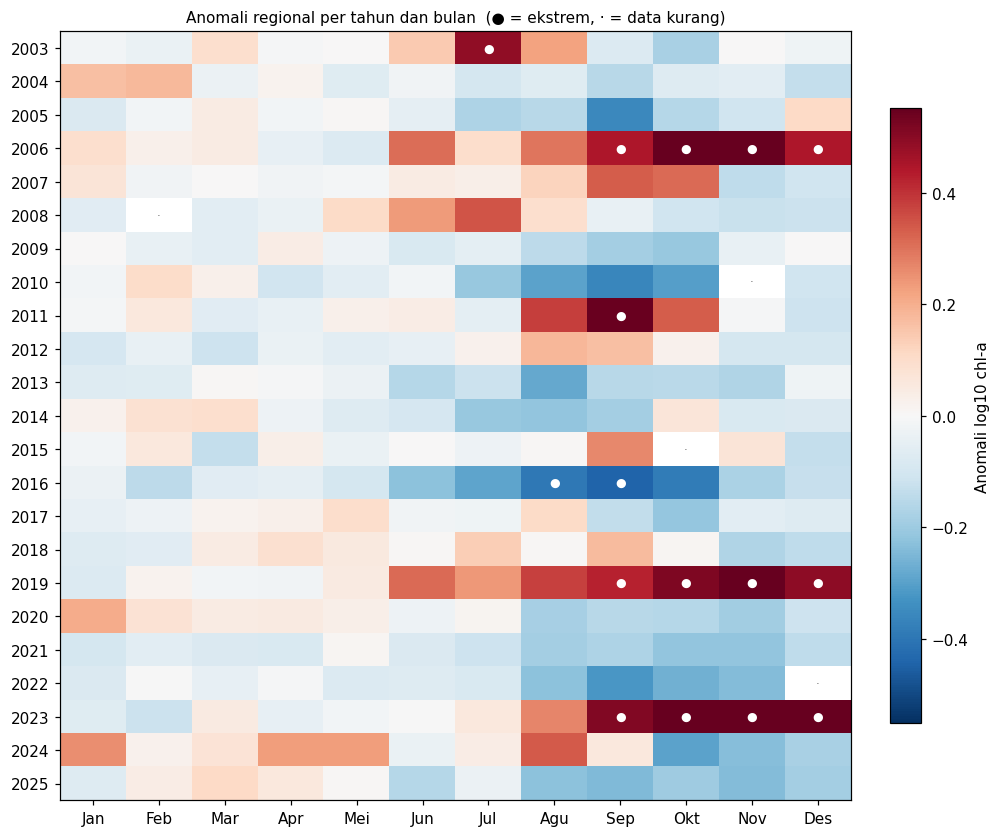

,anom_tahunan,anom_SON,anom_maks,anom_min,n_ekstrem_pos,n_ekstrem_neg,n_meluas,bulan_tersedia,kategori
year,,,,,,,,,
2003,0.051,-0.084,0.489,-0.181,1,0,2,12,ekstrem positif
2004,-0.028,-0.095,0.177,-0.155,0,0,1,12,normal
2005,-0.079,-0.208,0.108,-0.356,0,0,0,12,normal
2006,0.235,0.542,0.623,-0.074,4,0,6,12,ekstrem positif
2007,0.051,0.169,0.336,-0.140,0,0,2,12,normal
2008,0.021,-0.091,0.347,-0.125,0,0,2,11,normal
2009,-0.067,-0.146,0.043,-0.209,0,0,0,12,normal
2010,-0.123,-0.332,0.100,-0.361,0,0,0,11,normal
2011,0.092,0.291,0.545,-0.115,1,0,3,12,ekstrem positif


Tahun ekstrem positif: [2003, 2006, 2011, 2019, 2023]
Tahun ekstrem negatif: [2016]


In [5]:
H = ts.pivot(index='year', columns='cal_month', values='anom_reg')
vmax = np.nanpercentile(np.abs(H.to_numpy()), 98)
fig, ax = plt.subplots(figsize=(9, 7.5), constrained_layout=True)
im = ax.imshow(H.to_numpy(), cmap='RdBu_r', vmin=-vmax, vmax=vmax, aspect='auto')
ax.set_xticks(range(12)); ax.set_xticklabels(['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des'])
ax.set_yticks(range(len(H.index))); ax.set_yticklabels(H.index)
for (i, j), v in np.ndenumerate(H.to_numpy()):
    if np.isnan(v):
        ax.text(j, i, '·', ha='center', va='center', fontsize=8, color='gray')
    elif abs(v) > EXTREME_Z * SD:
        ax.text(j, i, '●', ha='center', va='center', fontsize=8, color='white' if abs(v) > .6 * vmax else 'black')
fig.colorbar(im, ax=ax, label='Anomali log10 chl-a', shrink=.8)
ax.set_title(f'Anomali regional per tahun dan bulan  (● = ekstrem, · = data kurang)', fontsize=10); ax.grid(False)
save_fig(fig, 'heatmap_tahun_bulan'); plt.show()

yr = ts.groupby('year').agg(
    anom_tahunan=('anom_reg', 'mean'),
    anom_SON=('anom_reg', lambda s: s[ts.loc[s.index, 'season'] == 'SON'].mean()),
    anom_maks=('anom_reg', 'max'),
    anom_min=('anom_reg', 'min'),
    n_ekstrem_pos=('ekstrem_pos', 'sum'),
    n_ekstrem_neg=('ekstrem_neg', 'sum'),
    n_meluas=('meluas', 'sum'),
    bulan_tersedia=('anom_reg', lambda s: int(s.notna().sum())),
)
def kategori(r):
    if r.n_ekstrem_pos > 0:
        return 'ekstrem positif'
    if r.n_ekstrem_neg > 0:
        return 'ekstrem negatif'
    return 'normal'
yr['kategori'] = yr.apply(kategori, axis=1)
display(yr.round(3))
save_table(yr, 'ringkasan_per_tahun')
EVENT_POS = sorted(yr.index[yr.kategori == 'ekstrem positif'])
EVENT_NEG = sorted(yr.index[yr.kategori == 'ekstrem negatif'])
print('Tahun ekstrem positif:', EVENT_POS)
print('Tahun ekstrem negatif:', EVENT_NEG)

## 4. Pola per periode (rolling)

Rata-rata dan simpangan baku bergerak 36 bulan dari anomali regional. Bila keduanya relatif datar, data tidak mengalami pergeseran rezim besar dan klimatologi train dapat dipakai untuk periode setelahnya. Lonjakan simpangan baku menandakan periode yang lebih bergejolak.

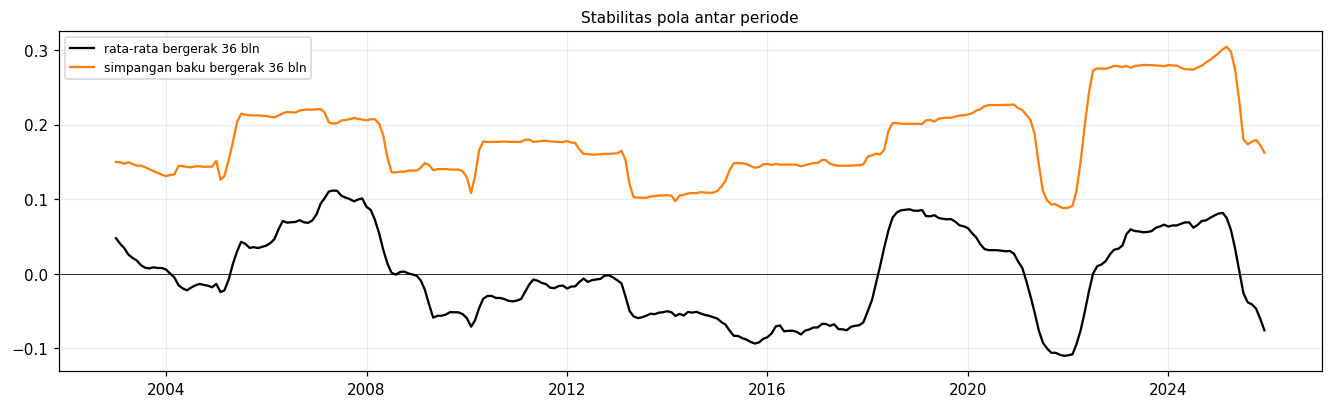

,rata_anom,sd_anom,n_ekstrem_pos,n_ekstrem_neg
periode,,,,
2003-2007,0.046,0.192,5,0
2008-2012,-0.017,0.159,1,0
2013-2017,-0.078,0.128,0,2
2018-2022,-0.003,0.197,4,0
2023-2025,0.062,0.274,4,0


In [6]:
W = 36
roll = pd.DataFrame({'rata-rata': ts.anom_reg.rolling(W, min_periods=W // 2, center=True).mean(),
                     'simpangan baku': ts.anom_reg.rolling(W, min_periods=W // 2, center=True).std()})
fig, ax = plt.subplots(figsize=(12, 3.6), constrained_layout=True)
ax.plot(roll.index, roll['rata-rata'], color='black', label='rata-rata bergerak 36 bln')
ax.plot(roll.index, roll['simpangan baku'], color='tab:orange', label='simpangan baku bergerak 36 bln')
ax.axhline(0, color='k', lw=.5); ax.legend(fontsize=8)
ax.set_title('Stabilitas pola antar periode', fontsize=10)
save_fig(fig, 'rolling_stats'); plt.show()

per5 = ts.groupby((ts.year - ts.year.min()) // 5).agg(
    periode=('year', lambda s: f'{s.min()}-{s.max()}'),
    rata_anom=('anom_reg', 'mean'), sd_anom=('anom_reg', 'std'),
    n_ekstrem_pos=('ekstrem_pos', 'sum'), n_ekstrem_neg=('ekstrem_neg', 'sum')).set_index('periode')
display(per5.round(3))
save_table(per5, 'ringkasan_per_5_tahun')

## 5. (Opsional) Cocokkan dengan indeks iklim

Untuk memastikan kejadian ekstrem di data chl-a memang terkait iklim (bukan galat satelit), cocokkan dengan **DMI** (Dipole Mode Index, untuk IOD) dan **ONI** (Oceanic Niño Index, untuk ENSO). Simpan sebagai CSV di `INDEX_PATH` dengan kolom `month` (format `YYYY-MM`) dan satu atau lebih kolom indeks, misalnya `dmi`, `oni`. Bagian ini dilewati otomatis bila file belum ada.

Sumber: NOAA PSL (DMI), NOAA CPC (ONI), atau Bureau of Meteorology Australia.

r         r_SON       
indeks       dmi    oni    dmi    oni
lag_bulan                            
0          0.654  0.345  0.835  0.485
1          0.617  0.301  0.785  0.489
2          0.494  0.238  0.674  0.485
3          0.357  0.167  0.543  0.446

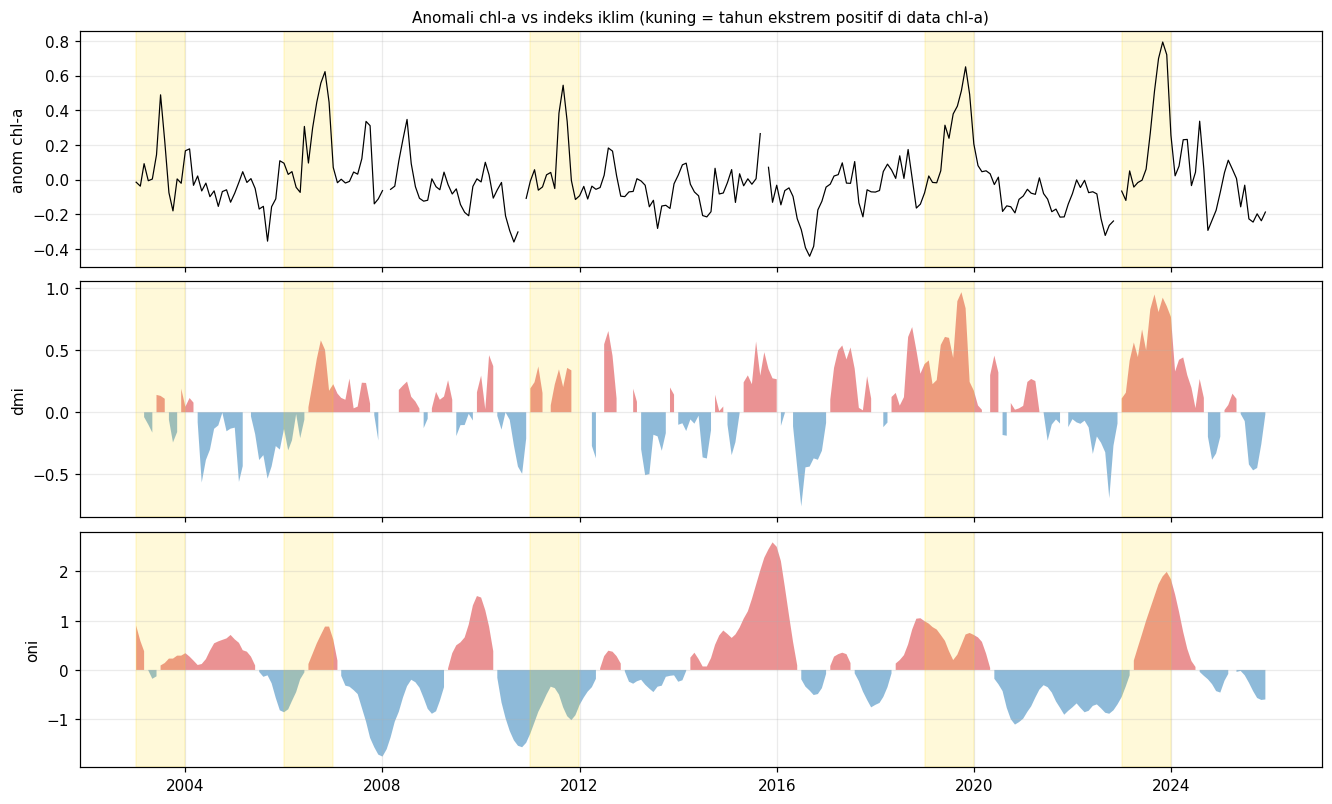

In [7]:
idx = None
if INDEX_PATH.is_file():
    idx = pd.read_csv(INDEX_PATH)
    idx['month'] = pd.to_datetime(idx.month.astype(str).str[:7] + '-01')
    idx = idx.set_index('month').reindex(ts.index)
    cols = [c for c in idx.columns if pd.api.types.is_numeric_dtype(idx[c])]
    rows = []
    for c in cols:
        for lag in range(0, 4):
            rows.append({'indeks': c, 'lag_bulan': lag, 'r': ts.anom_reg.corr(idx[c].shift(lag)),
                         'r_SON': ts.anom_reg[ts.season == 'SON'].corr(idx[c].shift(lag)[ts.season == 'SON'])})
    corr = pd.DataFrame(rows)
    display(corr.pivot(index='lag_bulan', columns='indeks', values=['r', 'r_SON']).round(3))
    save_table(corr, 'korelasi_indeks_iklim', index=False)

    fig, axes = plt.subplots(len(cols) + 1, 1, figsize=(12, 2.4 * (len(cols) + 1)), sharex=True, constrained_layout=True)
    axes = np.atleast_1d(axes)
    axes[0].plot(ts.index, ts.anom_reg, color='black', lw=.8); axes[0].set_ylabel('anom chl-a')
    for a, c in zip(axes[1:], cols):
        a.fill_between(idx.index, 0, idx[c], where=idx[c] > 0, color='tab:red', alpha=.5, lw=0)
        a.fill_between(idx.index, 0, idx[c], where=idx[c] < 0, color='tab:blue', alpha=.5, lw=0)
        a.set_ylabel(c)
    for a in axes:
        for y in EVENT_POS:
            a.axvspan(pd.Timestamp(f'{y}-01-01'), pd.Timestamp(f'{y}-12-31'), color='gold', alpha=.15)
    axes[0].set_title('Anomali chl-a vs indeks iklim (kuning = tahun ekstrem positif di data chl-a)', fontsize=10)
    save_fig(fig, 'chla_vs_indeks_iklim'); plt.show()
else:
    print('File indeks iklim belum ada; bagian ini dilewati.')

## 6. Bandingkan kandidat split

Untuk setiap kandidat dihitung, per bagian (train, validasi, test):

- jumlah tahun dan bulan serta proporsinya,
- tahun ekstrem positif/negatif yang tercakup,
- rata-rata dan simpangan baku anomali,
- jumlah bulan per musim (cek keseimbangan musim),
- **jarak KS** antara distribusi anomali train dan bagian lain (0 = identik; makin besar makin berbeda),
- apakah dipotong di batas tahun.

Lalu setiap kandidat dicek terhadap kriteria di awal notebook.

In [8]:
def ks_distance(a, b):
    a, b = np.sort(a[~np.isnan(a)]), np.sort(b[~np.isnan(b)])
    if len(a) == 0 or len(b) == 0:
        return np.nan
    grid = np.concatenate([a, b])
    return float(np.max(np.abs(np.searchsorted(a, grid, 'right') / len(a) - np.searchsorted(b, grid, 'right') / len(b))))

def resolve(cfg):
    months = ts.index
    if cfg.get('frac'):
        k = int(len(months) * cfg['frac'])
        return months[k - 1], None
    te = pd.Timestamp(cfg['train_end'] + '-01')
    ve = pd.Timestamp(cfg['val_end'] + '-01') if cfg.get('val_end') else None
    return te, ve

def assign(cfg):
    te, ve = resolve(cfg)
    lab = pd.Series('test', index=ts.index)
    lab[ts.index <= te] = 'train'
    if ve is not None:
        lab[(ts.index > te) & (ts.index <= ve)] = 'val'
    return lab, te, ve

rows, labels = [], {}
for name, cfg in CANDIDATES.items():
    lab, te, ve = assign(cfg)
    labels[name] = lab
    tr_vals = ts.anom_reg[lab == 'train'].to_numpy()
    for part in ['train', 'val', 'test']:
        sel = lab == part
        if not sel.any():
            continue
        d = ts[sel]
        yrs = sorted(d.year.unique())
        rows.append({
            'kandidat': name, 'bagian': part,
            'periode': f'{d.index.min():%Y-%m} s.d. {d.index.max():%Y-%m}',
            'n_bulan': int(sel.sum()), 'proporsi': sel.mean(),
            'tahun_ekstrem_pos': ', '.join(str(y) for y in yrs if y in EVENT_POS) or '-',
            'tahun_ekstrem_neg': ', '.join(str(y) for y in yrs if y in EVENT_NEG) or '-',
            'n_bulan_ekstrem': int((d.ekstrem_pos | d.ekstrem_neg).sum()),
            'rata_anom': d.anom_reg.mean(), 'sd_anom': d.anom_reg.std(),
            'ks_vs_train': np.nan if part == 'train' else ks_distance(tr_vals, d.anom_reg.to_numpy()),
            **{f'n_{s}': int((d.season == s).sum()) for s in ['DJF', 'MAM', 'JJA', 'SON']},
        })
comp = pd.DataFrame(rows)
display(comp.round(3))
save_table(comp, 'perbandingan_kandidat_split', index=False)

,kandidat,bagian,periode,n_bulan,proporsi,tahun_ekstrem_pos,tahun_ekstrem_neg,n_bulan_ekstrem,rata_anom,sd_anom,ks_vs_train,n_DJF,n_MAM,n_JJA,n_SON
0,Baku 80:20,train,2003-01 s.d. 2021-04,220,0.797,"2003, 2006, 2011, 2019",2016,12,-0.002,0.178,NaN,56,56,54,54
1,Baku 80:20,test,2021-05 s.d. 2025-12,56,0.203,2023,-,4,-0.006,0.246,0.198,13,13,15,15
2,Split EDA (s.d. 2018),train,2003-01 s.d. 2018-12,192,0.696,"2003, 2006, 2011",2016,8,-0.015,0.165,NaN,48,48,48,48
3,Split EDA (s.d. 2018),test,2019-01 s.d. 2025-12,84,0.304,"2019, 2023",-,8,0.023,0.243,0.125,21,21,21,21
4,Usulan A (2016|2020),train,2003-01 s.d. 2016-12,168,0.609,"2003, 2006, 2011",2016,8,-0.015,0.173,NaN,42,42,42,42
5,Usulan A (2016|2020),val,2017-01 s.d. 2020-12,48,0.174,2019,-,4,0.048,0.191,0.259,12,12,12,12
6,Usulan A (2016|2020),test,2021-01 s.d. 2025-12,60,0.217,2023,-,4,-0.011,0.238,0.167,15,15,15,15
7,Usulan B (2017|2020),train,2003-01 s.d. 2017-12,180,0.652,"2003, 2006, 2011",2016,8,-0.016,0.169,NaN,45,45,45,45
8,Usulan B (2017|2020),val,2018-01 s.d. 2020-12,36,0.130,2019,-,4,0.074,0.209,0.334,9,9,9,9
9,Usulan B (2017|2020),test,2021-01 s.d. 2025-12,60,0.217,2023,-,4,-0.011,0.238,0.169,15,15,15,15


In [9]:
crit_rows = []
for name, cfg in CANDIDATES.items():
    lab, te, ve = assign(cfg)
    c = comp[comp.kandidat == name].set_index('bagian')
    has_val = 'val' in c.index
    parts = [b for b in ['train', 'val', 'test'] if b in c.index]
    ev_each = all(c.loc[b, 'tahun_ekstrem_pos'] != '-' for b in parts)
    season_ok = all(c.loc[b, ['n_DJF', 'n_MAM', 'n_JJA', 'n_SON']].nunique() == 1 for b in parts)
    year_cut = (te.month == 12) and (ve is None or ve.month == 12)
    train_years = c.loc['train', 'n_bulan'] / 12
    ks_max = c.drop(index='train').ks_vs_train.max()
    crit_rows.append({
        'kandidat': name,
        'ada validasi': has_val,
        'potong di batas tahun': year_cut,
        'musim seimbang tiap bagian': season_ok,
        'ekstrem positif di tiap bagian': ev_each,
        'train >= 12 tahun': train_years >= 12,
        'KS maks vs train': round(float(ks_max), 3),
        'proporsi train:val:test': ':'.join(f'{c.loc[b, "proporsi"] * 100:.0f}' if b in c.index else '0' for b in ['train', 'val', 'test']),
    })
crit = pd.DataFrame(crit_rows).set_index('kandidat')
bool_cols = ['ada validasi', 'potong di batas tahun', 'musim seimbang tiap bagian', 'ekstrem positif di tiap bagian', 'train >= 12 tahun']
crit['kriteria terpenuhi'] = crit[bool_cols].sum(axis=1).astype(str) + f'/{len(bool_cols)}'
display(crit)
save_table(crit, 'kriteria_kandidat_split')

,ada validasi,potong di batas tahun,musim seimbang tiap bagian,ekstrem positif di tiap bagian,train >= 12 tahun,KS maks vs train,proporsi train:val:test,kriteria terpenuhi
kandidat,,,,,,,,
Baku 80:20,False,False,False,True,True,0.198,80:0:20,2/5
Split EDA (s.d. 2018),False,True,True,True,True,0.125,70:0:30,4/5
Usulan A (2016|2020),True,True,True,True,True,0.259,61:17:22,5/5
Usulan B (2017|2020),True,True,True,True,True,0.334,65:13:22,5/5
Usulan C (2015|2019),True,True,True,True,True,0.190,57:17:26,5/5
Usulan D (2016|2019),True,True,True,True,True,0.280,61:13:26,5/5


### Visualisasi kandidat split

Setiap baris adalah satu kandidat. Warna menunjukkan bagian (train, validasi, test), dan titik merah menandai bulan ekstrem positif. Dari sini terlihat langsung apakah kejadian ekstrem tersebar ke semua bagian atau menumpuk di satu bagian.

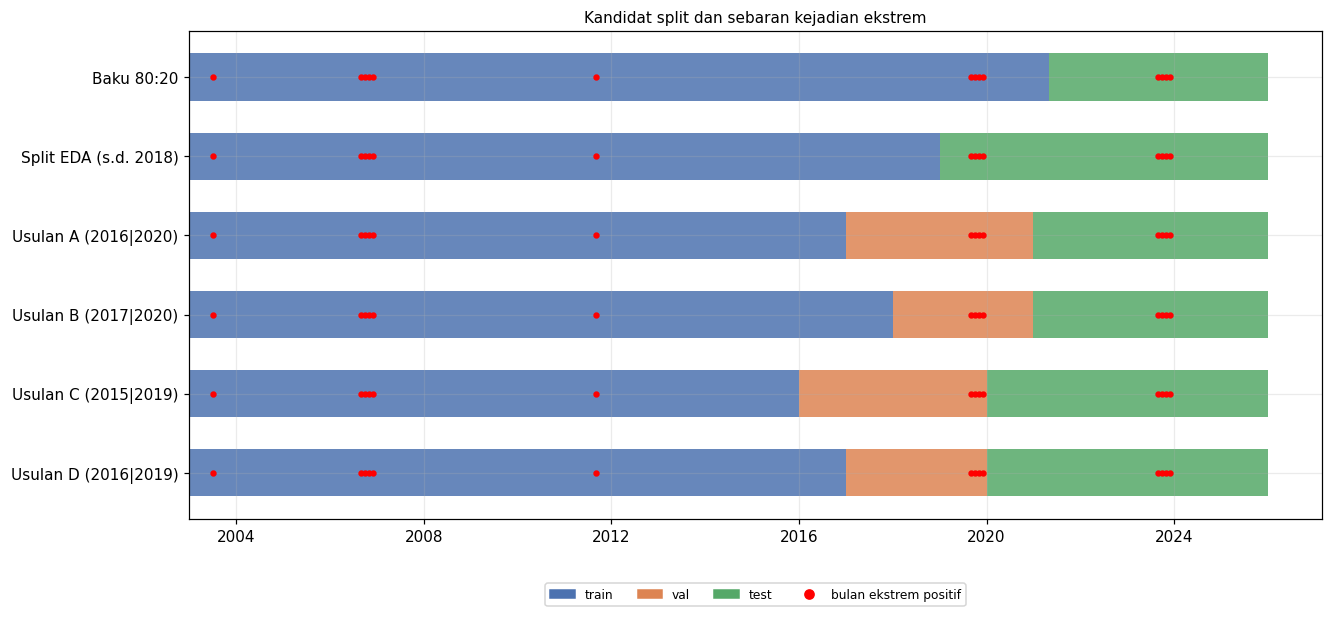

In [10]:
colors = {'train': '#4C72B0', 'val': '#DD8452', 'test': '#55A868'}
names = list(CANDIDATES)
fig, ax = plt.subplots(figsize=(12, 0.65 * len(names) + 1.6), constrained_layout=True)
for i, name in enumerate(names):
    lab = labels[name]
    for part, col in colors.items():
        sel = lab == part
        if sel.any():
            ax.barh(i, (lab.index[sel].max() - lab.index[sel].min()).days + 31, left=lab.index[sel].min(),
                    height=.6, color=col, alpha=.85)
    ev = ts.index[ts.ekstrem_pos]
    ax.scatter(ev, np.full(len(ev), i), color='red', s=10, zorder=3)
ax.set_yticks(range(len(names))); ax.set_yticklabels(names); ax.invert_yaxis()
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
handles = [Patch(color=c, label=k) for k, c in colors.items()] + [Line2D([], [], marker='o', ls='', color='red', label='bulan ekstrem positif')]
ax.legend(handles=handles, ncol=4, fontsize=8, loc='upper center', bbox_to_anchor=(.5, -.12))
ax.set_title('Kandidat split dan sebaran kejadian ekstrem', fontsize=10)
save_fig(fig, 'kandidat_split'); plt.show()

## 7. Pilih split dan simpan

Setelah meninjau tabel kriteria dan grafik di atas (dan berdiskusi dengan dosen pembimbing), tulis kandidat terpilih di `SELECTED`. Konfigurasi disimpan ke JSON. Langkah berikutnya: buka notebook cleaning, ubah `TRAIN_END` sesuai `train_end` terpilih, lalu jalankan ulang supaya klimatologi, ρ, dan ambang outlier dihitung ulang dari periode train yang baru.

In [ ]:
SELECTED = 'Usulan A (2016|2020)'   # ganti setelah diputuskan

lab, te, ve = assign(CANDIDATES[SELECTED])
out = {
    'region': REGION, 'tag': TAG, 'kandidat': SELECTED,
    'train': [f'{lab.index[lab == "train"].min():%Y-%m}', f'{te:%Y-%m}'],
    'val': [f'{lab.index[lab == "val"].min():%Y-%m}', f'{ve:%Y-%m}'] if ve is not None else None,
    'test': [f'{lab.index[lab == "test"].min():%Y-%m}', f'{lab.index[lab == "test"].max():%Y-%m}'],
    'tahun_ekstrem_positif': [int(y) for y in EVENT_POS],
    'tahun_ekstrem_negatif': [int(y) for y in EVENT_NEG],
    'kriteria': {k: (bool(v) if isinstance(v, (bool, np.bool_)) else v) for k, v in crit.loc[SELECTED].items()},
    'catatan': 'Jalankan ulang notebook cleaning dengan TRAIN_END = train[1] sebelum pemodelan.',
}
p_out = ROOT / 'data' / 'processed' / 'clean' / f'split_{REGION}_{TAG}.json'
with open(p_out, 'w', encoding='utf-8') as f:
    json.dump(out, f, indent=2, ensure_ascii=False)
print(json.dumps(out, indent=2, ensure_ascii=False))
print('Disimpan ke', p_out)